CUSTOMER SUPPORT DATASET - PHASE 1

Dataset loaded successfully!

--- FIRST 5 ROWS ---
      TicketID CustomerID         IssueType Priority       Channel  \
0  TKT00000001  CUS000001   Feature Request     High         Email   
1  TKT00000002    Unknown   Product Inquiry   Medium          Chat   
2  TKT00000003    Unknown         API Issue   Medium  Social Media   
3  TKT00000004  CUS000004  Delivery Problem     High          Chat   
4  TKT00000005  CUS000005  Delivery Problem      Low  Social Media   

           CreatedDate         ResolvedDate  ResolutionTimeHours AgentID  \
0  2024-02-02 00:05:00                  NaN                  NaN  AGT048   
1  2025-12-15 13:21:00  2025-12-18 13:21:00                 72.0  AGT029   
2  2025-10-05 19:56:00                  NaN                  NaN  AGT017   
3  2024-08-02 21:17:00  2024-08-09 19:17:00                166.0  AGT007   
4  2024-10-01 02:13:00                  NaN                  NaN  AGT015   

   AgentExperience       Status  Es

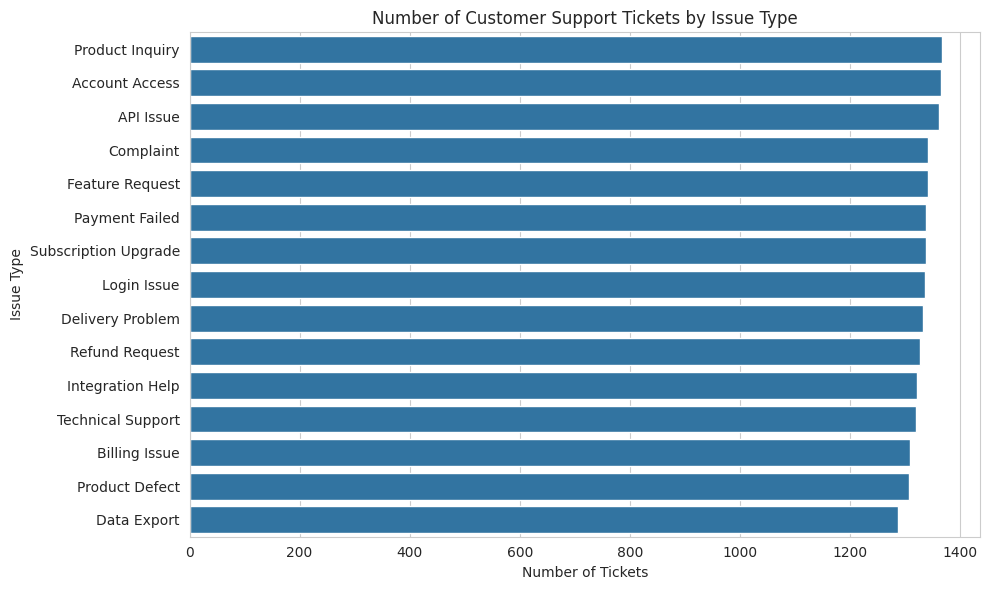

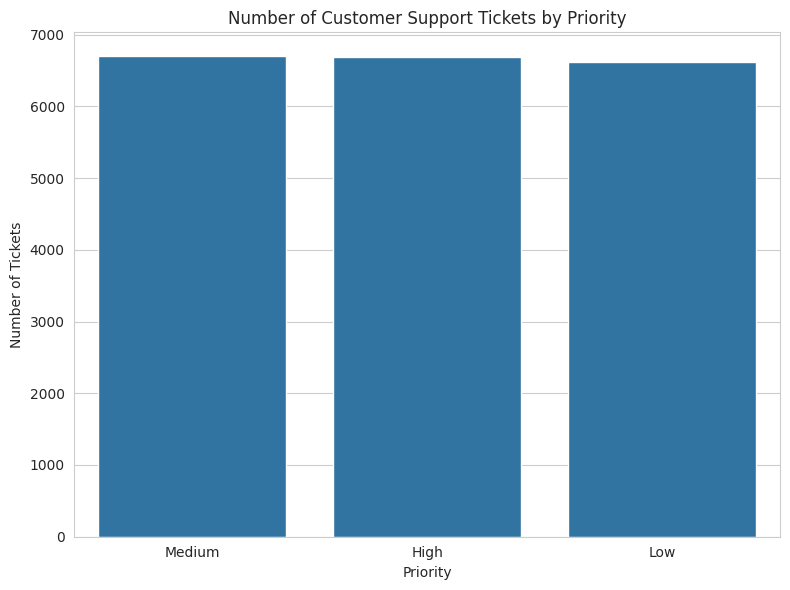

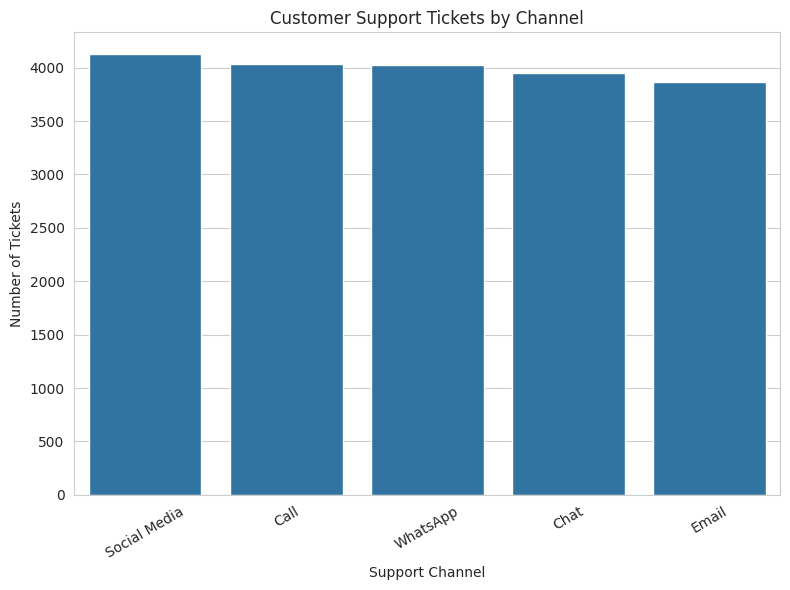

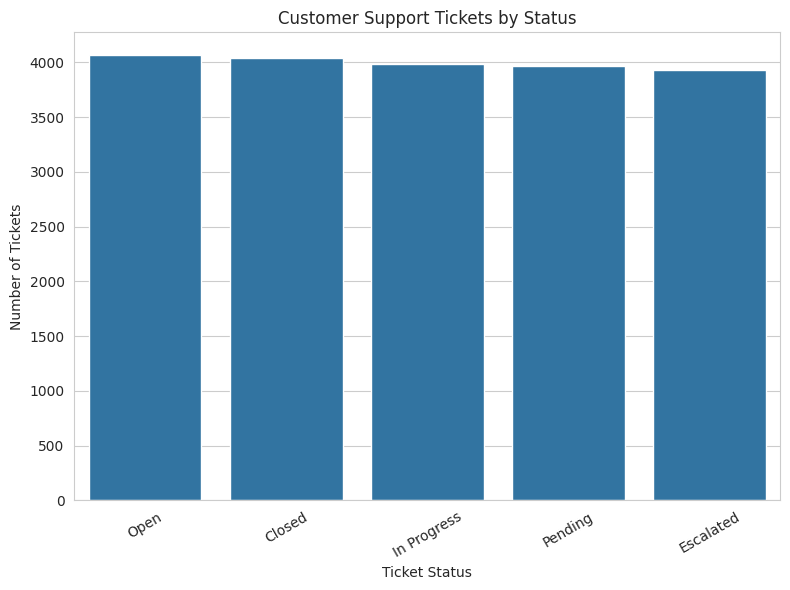

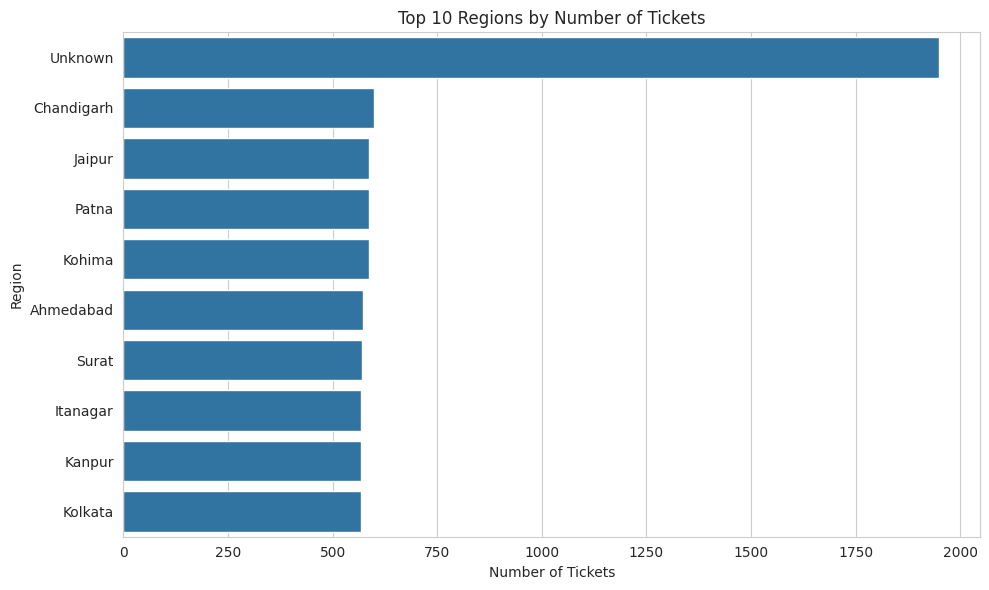

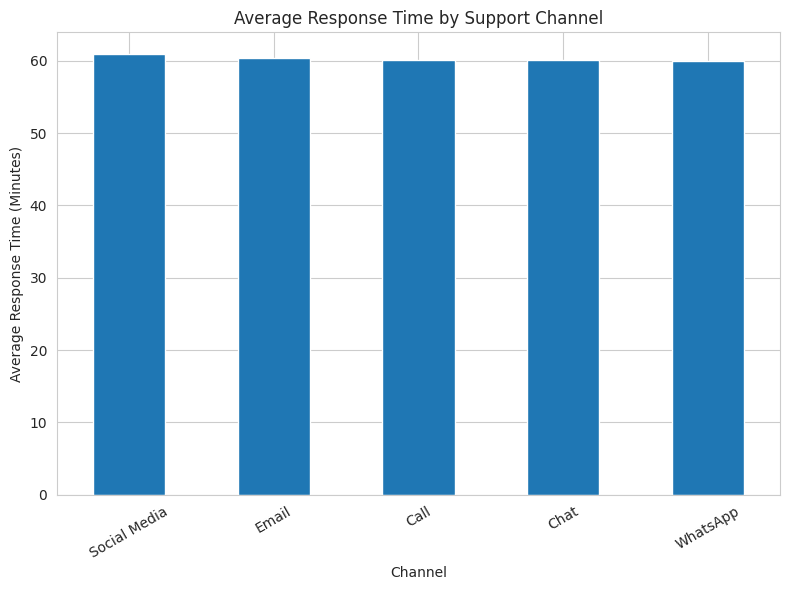

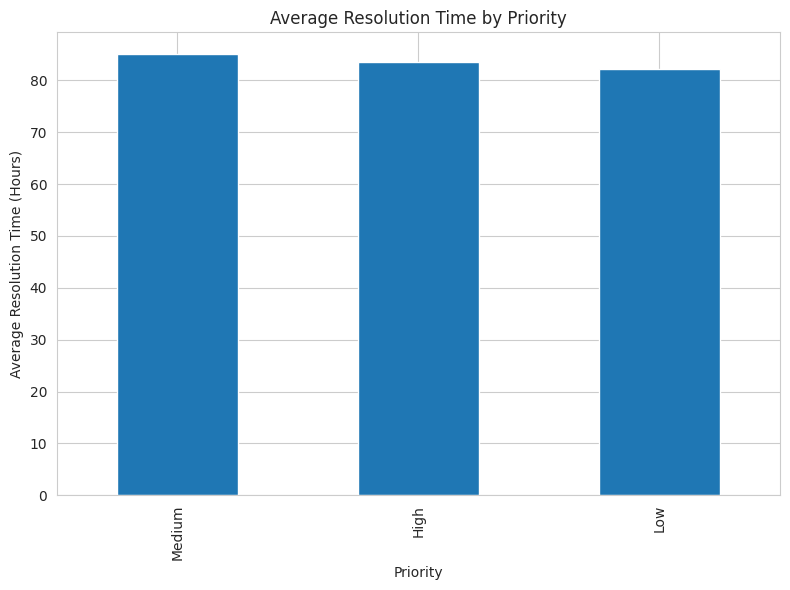

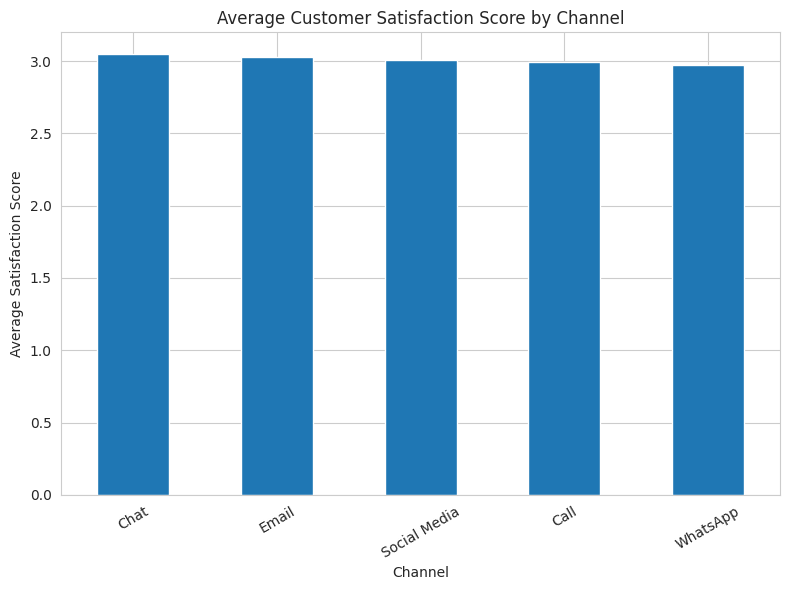

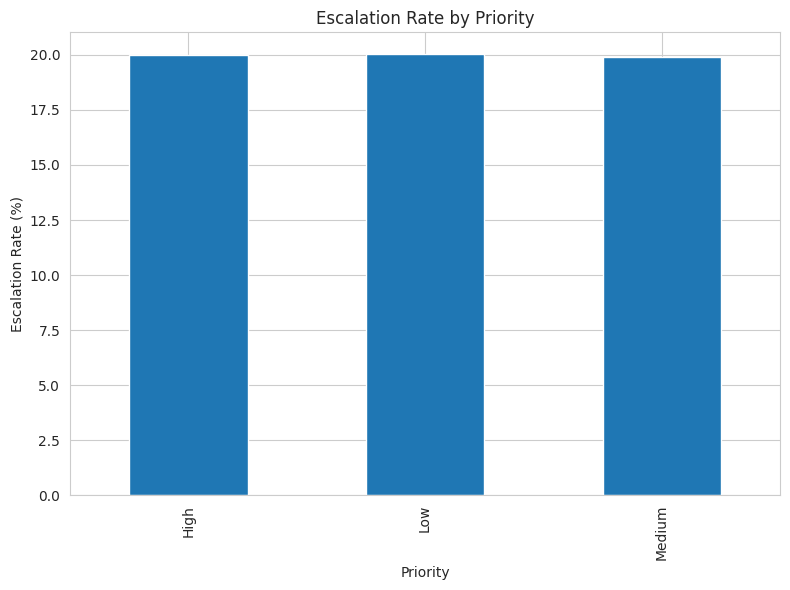


--- MOST COMMON ISSUE ---
Most common issue: Product Inquiry
Number of tickets: 1368

--- MOST USED CHANNEL ---
Most used channel: Social Media

--- MOST COMMON PRIORITY ---
Most common priority: Medium

--- OVERALL AVERAGE RESPONSE TIME ---
Average response time: 60.27 minutes

--- OVERALL AVERAGE SATISFACTION ---
Average satisfaction: 3.01

--- OVERALL AVERAGE RESOLUTION TIME ---
Average resolution time: 83.6 hours


FINAL DATASET CHECK

Original dataset shape:
(20000, 16)

Cleaned dataset shape:
(20000, 16)

Duplicates remaining:
0

Missing values:
TicketID                     0
CustomerID                   0
IssueType                    0
Priority                     0
Channel                      0
CreatedDate                  0
ResolvedDate             12837
ResolutionTimeHours      12120
AgentID                      0
AgentExperience              0
Status                       0
EscalationFlag               0
SatisfactionScore         4726
ResponseTimeMinutes          0
Region 

In [6]:
# ============================================================
# CUSTOMER SUPPORT DATASET
# PROJECT PHASE - 1
# Data Exploration, Cleaning, Analysis, Visualization
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ------------------------------------------------------------
# 2. LOAD DATASET
# ------------------------------------------------------------

df = pd.read_csv("customer_support_dataset_cleaned.csv")

print("=" * 70)
print("CUSTOMER SUPPORT DATASET - PHASE 1")
print("=" * 70)

print("\nDataset loaded successfully!")


# ============================================================
# PART A - DATASET EXPLORATION
# ============================================================

# ------------------------------------------------------------
# 3. DISPLAY FIRST 5 ROWS
# ------------------------------------------------------------

print("\n--- FIRST 5 ROWS ---")
print(df.head())


# ------------------------------------------------------------
# 4. DISPLAY LAST 5 ROWS
# ------------------------------------------------------------

print("\n--- LAST 5 ROWS ---")
print(df.tail())


# ------------------------------------------------------------
# 5. NUMBER OF ROWS AND COLUMNS
# ------------------------------------------------------------

print("\n--- DATASET SHAPE ---")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


# ------------------------------------------------------------
# 6. COLUMN NAMES
# ------------------------------------------------------------

print("\n--- COLUMN NAMES ---")

for column in df.columns:
    print(column)


# ------------------------------------------------------------
# 7. DATA TYPES
# ------------------------------------------------------------

print("\n--- DATA TYPES ---")
print(df.dtypes)


# ------------------------------------------------------------
# 8. BASIC INFORMATION
# ------------------------------------------------------------

print("\n--- DATASET INFORMATION ---")
print(df.info())


# ------------------------------------------------------------
# 9. STATISTICAL SUMMARY
# ------------------------------------------------------------

print("\n--- STATISTICAL SUMMARY ---")
print(df.describe())


# ------------------------------------------------------------
# 10. MISSING VALUES
# ------------------------------------------------------------

print("\n--- MISSING VALUES ---")

missing_values = df.isnull().sum()

print(missing_values)


# ------------------------------------------------------------
# 11. MISSING VALUE PERCENTAGE
# ------------------------------------------------------------

print("\n--- MISSING VALUE PERCENTAGE ---")

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)


# ------------------------------------------------------------
# 12. DUPLICATE RECORDS
# ------------------------------------------------------------

print("\n--- DUPLICATE RECORDS ---")

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


# ============================================================
# PART B - DATA CLEANING
# ============================================================

print("\n")
print("=" * 70)
print("DATA CLEANING")
print("=" * 70)


# ------------------------------------------------------------
# 13. MAKE A COPY OF DATASET
# ------------------------------------------------------------

cleaned_df = df.copy()


# ------------------------------------------------------------
# 14. REMOVE DUPLICATES
# ------------------------------------------------------------

cleaned_df = cleaned_df.drop_duplicates()

print("\nDuplicate records removed.")


# ------------------------------------------------------------
# 15. CONVERT DATE COLUMNS TO DATETIME
# ------------------------------------------------------------

cleaned_df["CreatedDate"] = pd.to_datetime(
    cleaned_df["CreatedDate"],
    errors="coerce"
)

cleaned_df["ResolvedDate"] = pd.to_datetime(
    cleaned_df["ResolvedDate"],
    errors="coerce"
)

print("\nDate columns converted to datetime.")


# ------------------------------------------------------------
# 16. HANDLE MISSING CUSTOMER IDs
# ------------------------------------------------------------

cleaned_df["CustomerID"] = cleaned_df["CustomerID"].fillna("Unknown")


# ------------------------------------------------------------
# 17. HANDLE MISSING REGION
# ------------------------------------------------------------

cleaned_df["Region"] = cleaned_df["Region"].fillna("Unknown")


# ------------------------------------------------------------
# 18. CALCULATE MISSING RESOLUTION TIME
# ------------------------------------------------------------

calculated_resolution_time = (
    cleaned_df["ResolvedDate"] -
    cleaned_df["CreatedDate"]
).dt.total_seconds() / 3600


missing_resolution = (
    cleaned_df["ResolutionTimeHours"].isnull()
    & calculated_resolution_time.notnull()
)

cleaned_df.loc[
    missing_resolution,
    "ResolutionTimeHours"
] = calculated_resolution_time[missing_resolution]


# ------------------------------------------------------------
# 19. CHECK CLEANED DATA
# ------------------------------------------------------------

print("\n--- MISSING VALUES AFTER CLEANING ---")

print(cleaned_df.isnull().sum())


# ------------------------------------------------------------
# 20. CLEANED DATASET INFORMATION
# ------------------------------------------------------------

print("\n--- CLEANED DATASET INFO ---")

print(cleaned_df.info())


# ------------------------------------------------------------
# 21. SAVE CLEANED DATASET
# ------------------------------------------------------------

cleaned_df.to_csv(
    "customer_support_dataset_cleaned.csv",
    index=False
)

print("\nCleaned dataset saved successfully.")


# ============================================================
# PART C - DATA ANALYSIS
# ============================================================

print("\n")
print("=" * 70)
print("DATA ANALYSIS")
print("=" * 70)


# ------------------------------------------------------------
# 22. NUMBER OF TICKETS BY ISSUE TYPE
# ------------------------------------------------------------

print("\n--- TICKETS BY ISSUE TYPE ---")

issue_counts = cleaned_df["IssueType"].value_counts()

print(issue_counts)


# ------------------------------------------------------------
# 23. NUMBER OF TICKETS BY PRIORITY
# ------------------------------------------------------------

print("\n--- TICKETS BY PRIORITY ---")

priority_counts = cleaned_df["Priority"].value_counts()

print(priority_counts)


# ------------------------------------------------------------
# 24. NUMBER OF TICKETS BY CHANNEL
# ------------------------------------------------------------

print("\n--- TICKETS BY CHANNEL ---")

channel_counts = cleaned_df["Channel"].value_counts()

print(channel_counts)


# ------------------------------------------------------------
# 25. NUMBER OF TICKETS BY STATUS
# ------------------------------------------------------------

print("\n--- TICKETS BY STATUS ---")

status_counts = cleaned_df["Status"].value_counts()

print(status_counts)


# ------------------------------------------------------------
# 26. NUMBER OF TICKETS BY REGION
# ------------------------------------------------------------

print("\n--- TICKETS BY REGION ---")

region_counts = cleaned_df["Region"].value_counts()

print(region_counts)


# ------------------------------------------------------------
# 27. AVERAGE RESPONSE TIME BY CHANNEL
# ------------------------------------------------------------

print("\n--- AVERAGE RESPONSE TIME BY CHANNEL ---")

avg_response_channel = (
    cleaned_df
    .groupby("Channel")["ResponseTimeMinutes"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_response_channel)


# ------------------------------------------------------------
# 28. AVERAGE RESOLUTION TIME BY PRIORITY
# ------------------------------------------------------------

print("\n--- AVERAGE RESOLUTION TIME BY PRIORITY ---")

avg_resolution_priority = (
    cleaned_df
    .groupby("Priority")["ResolutionTimeHours"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_resolution_priority)


# ------------------------------------------------------------
# 29. AVERAGE SATISFACTION SCORE BY CHANNEL
# ------------------------------------------------------------

print("\n--- AVERAGE SATISFACTION BY CHANNEL ---")

avg_satisfaction_channel = (
    cleaned_df
    .groupby("Channel")["SatisfactionScore"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_satisfaction_channel)


# ------------------------------------------------------------
# 30. ESCALATION RATE BY PRIORITY
# ------------------------------------------------------------

print("\n--- ESCALATION RATE BY PRIORITY ---")

escalation_rate = (
    cleaned_df
    .groupby("Priority")["EscalationFlag"]
    .mean()
    * 100
)

print(escalation_rate)


# ============================================================
# PART D - VISUALIZATION
# ============================================================

print("\n")
print("=" * 70)
print("VISUALIZATION")
print("=" * 70)


# General visualization settings
sns.set_style("whitegrid")


# ============================================================
# CHART 1
# Tickets by Issue Type
# ============================================================

plt.figure(figsize=(10, 6))

sns.countplot(
    data=cleaned_df,
    y="IssueType",
    order=cleaned_df["IssueType"].value_counts().index
)

plt.title("Number of Customer Support Tickets by Issue Type")
plt.xlabel("Number of Tickets")
plt.ylabel("Issue Type")

plt.tight_layout()
plt.show()


# ============================================================
# CHART 2
# Tickets by Priority
# ============================================================

plt.figure(figsize=(8, 6))

sns.countplot(
    data=cleaned_df,
    x="Priority",
    order=cleaned_df["Priority"].value_counts().index
)

plt.title("Number of Customer Support Tickets by Priority")
plt.xlabel("Priority")
plt.ylabel("Number of Tickets")

plt.tight_layout()
plt.show()


# ============================================================
# CHART 3
# Tickets by Channel
# ============================================================

plt.figure(figsize=(8, 6))

sns.countplot(
    data=cleaned_df,
    x="Channel",
    order=cleaned_df["Channel"].value_counts().index
)

plt.title("Customer Support Tickets by Channel")
plt.xlabel("Support Channel")
plt.ylabel("Number of Tickets")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


# ============================================================
# CHART 4
# Tickets by Status
# ============================================================

plt.figure(figsize=(8, 6))

sns.countplot(
    data=cleaned_df,
    x="Status",
    order=cleaned_df["Status"].value_counts().index
)

plt.title("Customer Support Tickets by Status")
plt.xlabel("Ticket Status")
plt.ylabel("Number of Tickets")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


# ============================================================
# CHART 5
# Top 10 Regions by Ticket Count
# ============================================================

top_regions = (
    cleaned_df["Region"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_regions.values,
    y=top_regions.index
)

plt.title("Top 10 Regions by Number of Tickets")
plt.xlabel("Number of Tickets")
plt.ylabel("Region")

plt.tight_layout()
plt.show()


# ============================================================
# CHART 6
# Average Response Time by Channel
# ============================================================

plt.figure(figsize=(8, 6))

avg_response_channel.plot(
    kind="bar"
)

plt.title("Average Response Time by Support Channel")
plt.xlabel("Channel")
plt.ylabel("Average Response Time (Minutes)")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


# ============================================================
# CHART 7
# Average Resolution Time by Priority
# ============================================================

plt.figure(figsize=(8, 6))

avg_resolution_priority.plot(
    kind="bar"
)

plt.title("Average Resolution Time by Priority")
plt.xlabel("Priority")
plt.ylabel("Average Resolution Time (Hours)")

plt.tight_layout()
plt.show()


# ============================================================
# CHART 8
# Average Satisfaction Score by Channel
# ============================================================

plt.figure(figsize=(8, 6))

avg_satisfaction_channel.plot(
    kind="bar"
)

plt.title("Average Customer Satisfaction Score by Channel")
plt.xlabel("Channel")
plt.ylabel("Average Satisfaction Score")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


# ============================================================
# CHART 9
# Escalation Rate by Priority
# ============================================================

plt.figure(figsize=(8, 6))

escalation_rate.plot(
    kind="bar"
)

plt.title("Escalation Rate by Priority")
plt.xlabel("Priority")
plt.ylabel("Escalation Rate (%)")

plt.tight_layout()
plt.show()


# ============================================================
# PART E - ADDITIONAL ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 31. TOP ISSUE TYPE
# ------------------------------------------------------------

print("\n--- MOST COMMON ISSUE ---")

most_common_issue = issue_counts.idxmax()
most_common_issue_count = issue_counts.max()

print(
    "Most common issue:",
    most_common_issue
)

print(
    "Number of tickets:",
    most_common_issue_count
)


# ------------------------------------------------------------
# 32. MOST USED SUPPORT CHANNEL
# ------------------------------------------------------------

print("\n--- MOST USED CHANNEL ---")

most_used_channel = channel_counts.idxmax()

print(
    "Most used channel:",
    most_used_channel
)


# ------------------------------------------------------------
# 33. HIGHEST TICKET PRIORITY
# ------------------------------------------------------------

print("\n--- MOST COMMON PRIORITY ---")

most_common_priority = priority_counts.idxmax()

print(
    "Most common priority:",
    most_common_priority
)


# ------------------------------------------------------------
# 34. AVERAGE RESPONSE TIME
# ------------------------------------------------------------

print("\n--- OVERALL AVERAGE RESPONSE TIME ---")

overall_response_time = (
    cleaned_df["ResponseTimeMinutes"].mean()
)

print(
    "Average response time:",
    round(overall_response_time, 2),
    "minutes"
)


# ------------------------------------------------------------
# 35. AVERAGE SATISFACTION
# ------------------------------------------------------------

print("\n--- OVERALL AVERAGE SATISFACTION ---")

overall_satisfaction = (
    cleaned_df["SatisfactionScore"].mean()
)

print(
    "Average satisfaction:",
    round(overall_satisfaction, 2)
)


# ------------------------------------------------------------
# 36. AVERAGE RESOLUTION TIME
# ------------------------------------------------------------

print("\n--- OVERALL AVERAGE RESOLUTION TIME ---")

overall_resolution = (
    cleaned_df["ResolutionTimeHours"].mean()
)

print(
    "Average resolution time:",
    round(overall_resolution, 2),
    "hours"
)


# ============================================================
# PART F - FINAL DATASET CHECK
# ============================================================

print("\n")
print("=" * 70)
print("FINAL DATASET CHECK")
print("=" * 70)

print("\nOriginal dataset shape:")
print(df.shape)

print("\nCleaned dataset shape:")
print(cleaned_df.shape)

print("\nDuplicates remaining:")
print(cleaned_df.duplicated().sum())

print("\nMissing values:")
print(cleaned_df.isnull().sum())


print("\n")
print("=" * 70)
print("PHASE 1 COMPLETED")
print("=" * 70)